# Cell type selection pipeline test

In this notebook, the pipeline of selection of cell types is prototyped. Good way to test any conceptual changes to the procedure.
BUG: Results form this notebook and Package differ

In [19]:
# import os
# os.chdir('../')
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [20]:
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scipy
import pandas as pd
import json
import seaborn as sb

In [21]:
import itertools

In [60]:
from collections import defaultdict

In [22]:
workspace = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\MapAnalyzer_Results_2.0"

In [23]:
ad_storage = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\Adatas\\HLCA_full_v1.h5ad"

In [24]:
def set_clean_labels(obs):

    label_file = open(f"{workspace}\\label_mapping.txt")
    labels_dict = json.load(label_file)
    
    new_dict={}
    for k, v in labels_dict.items():
        if "_" in k:
            k = k.split("_")[1]
        if "_" in v:
            v = v.split("_")[1]
        new_dict[k]=v
    
    labels_dict=new_dict
    
    level_file = open(f"{workspace}\\label_mapping_levels.txt")
    levels_dict = json.load(level_file)

    obs["cell_label"] = obs.ann_finest_level

    obs["cell_label"] = obs.ann_finest_level.replace(labels_dict)

    obs["cell_label"] = obs["cell_label"].astype(str)

    obs["cell_label"] = obs["cell_label"].astype("category")
    # clean up labels from number prefixes
    clean_labels = {}
    for ct in obs.cell_label.cat.categories:
        if "_" in ct:
            ct_new = ct.split("_")[1]
        else:
            ct_new = ct
        clean_labels[ct] = ct_new

    obs["cell_label"] = obs["cell_label"].replace(clean_labels)
    level_file.close()
    label_file.close()
    return obs

In [40]:
adata= sc.read_h5ad(ad_storage)

In [41]:
adata_sub = adata[adata.obs.core_or_extension == "core"].copy()

In [11]:
del adata

NameError: name 'adata' is not defined

In [44]:
#del adata

In [46]:
adata_sub

AnnData object with n_obs × n_vars = 584944 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

In [47]:
sc.pp.neighbors(adata_sub,n_neighbors=15)

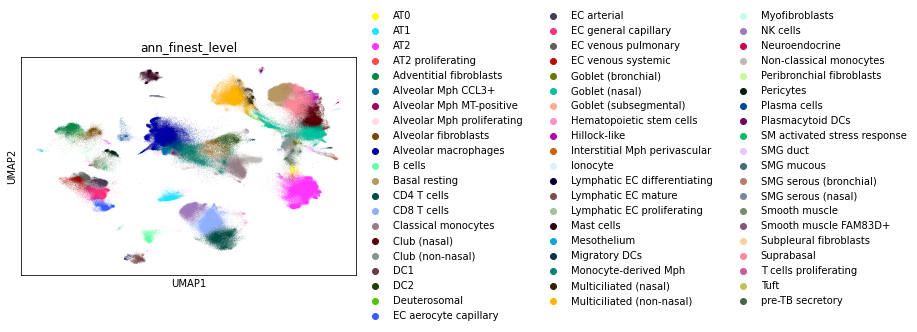

In [48]:
sc.pl.umap(adata_sub,color="ann_finest_level")

In [49]:
sc.set_figure_params(figsize=(20,20))

In [50]:
sc.tl.paga(adata_sub,groups=f"ann_finest_level")

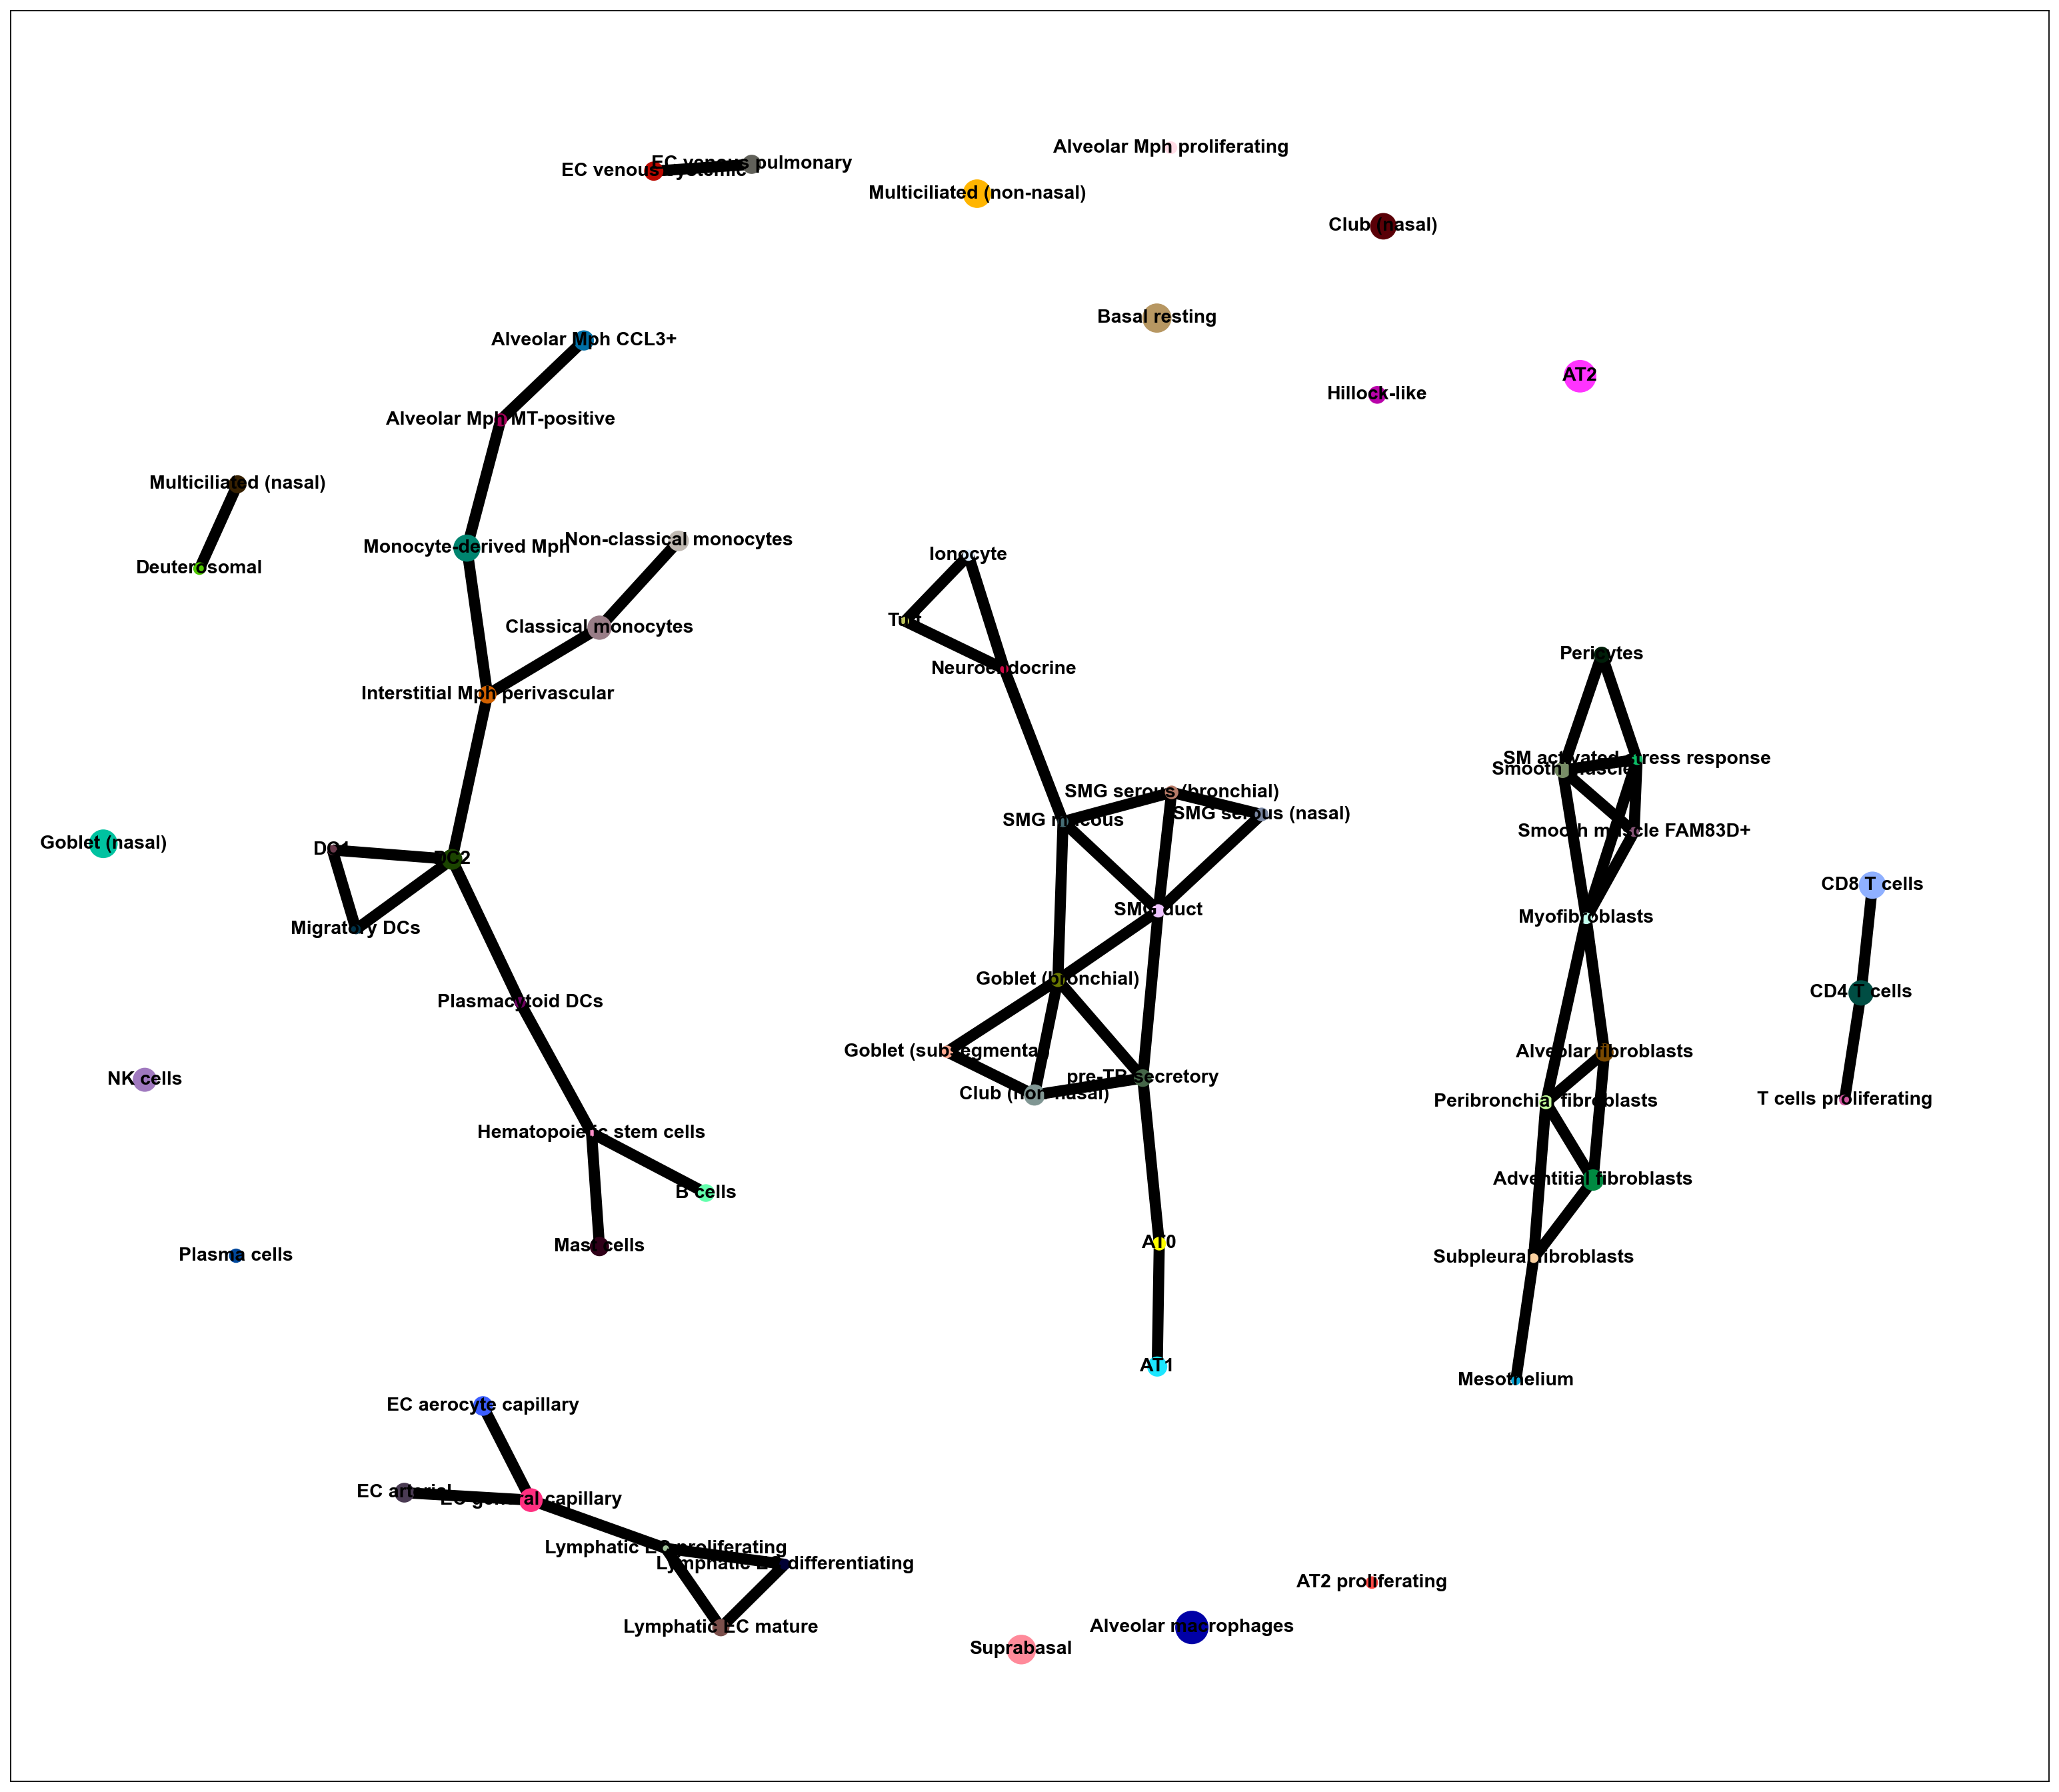

In [51]:
sc.pl.paga(adata_sub,threshold=1)

In [52]:
dict_parents={}

In [55]:
for i in range(5,1,-1):
    for cat in adata_sub.obs[f"ann_level_{i}"].cat.categories:
        parent = adata_sub.obs.loc[adata_sub.obs[f"ann_level_{i}"]==cat,f"ann_level_{i-1}"][0]
        dict_parents[cat]=parent

In [56]:
dict_parents

{'AT0': 'Transitional Club-AT2',
 'Alveolar Mph CCL3+': 'Alveolar macrophages',
 'Alveolar Mph MT-positive': 'Alveolar macrophages',
 'Alveolar Mph proliferating': 'Alveolar macrophages',
 'Club (nasal)': 'Club',
 'Club (non-nasal)': 'Club',
 'Goblet (bronchial)': 'Goblet',
 'Goblet (nasal)': 'Goblet',
 'Goblet (subsegmental)': 'Goblet',
 'Interstitial Mph perivascular': 'Interstitial macrophages',
 'Monocyte-derived Mph': 'Interstitial macrophages',
 'Multiciliated (nasal)': 'Multiciliated',
 'Multiciliated (non-nasal)': 'Multiciliated',
 'None': 'Smooth muscle',
 'SMG serous (bronchial)': 'SMG serous',
 'SMG serous (nasal)': 'SMG serous',
 'pre-TB secretory': 'Transitional Club-AT2',
 'AT2 proliferating': 'AT2',
 'Adventitial fibroblasts': 'Fibroblasts',
 'Alveolar fibroblasts': 'Fibroblasts',
 'Alveolar macrophages': 'Macrophages',
 'B cells': 'B cell lineage',
 'Basal resting': 'Basal',
 'CD4 T cells': 'T cell lineage',
 'CD8 T cells': 'T cell lineage',
 'Classical monocytes': 'Mon

In [62]:
#Fixing error in annotation
dict_parents['Pericytes'] = 'Smooth muscle'

In [63]:
del dict_parents["None"]

KeyError: 'None'

In [64]:
res = defaultdict(list)
for key, val in sorted(dict_parents.items()):
    res[val].append(key)
dict_children = res

In [65]:
dict_children

defaultdict(list,
            {'Transitional Club-AT2': ['AT0', 'pre-TB secretory'],
             'Alveolar epithelium': ['AT1', 'AT2'],
             'AT2': ['AT2 proliferating'],
             'Fibroblasts': ['Adventitial fibroblasts',
              'Alveolar fibroblasts',
              'Peribronchial fibroblasts',
              'Subpleural fibroblasts'],
             'Epithelial': ['Airway epithelium',
              'Alveolar epithelium',
              'Submucosal Gland'],
             'Alveolar macrophages': ['Alveolar Mph CCL3+',
              'Alveolar Mph MT-positive',
              'Alveolar Mph proliferating'],
             'Macrophages': ['Alveolar macrophages',
              'Interstitial macrophages'],
             'Lymphoid': ['B cell lineage',
              'Innate lymphoid cell NK',
              'T cell lineage'],
             'B cell lineage': ['B cells', 'Plasma cells'],
             'Airway epithelium': ['Basal',
              'Multiciliated lineage',
              'Ra

In [66]:
def get_edges(celltype_list):
    edges=[]
    for ct in celltype_list:
        for child in dict_children[ct]:
            edges.append((ct,child))
    return edges

In [67]:
def build_tree():#recursive tree building
    edges=[]
    for level in range(1,6):
        ct_list=adata_sub.obs[f"ann_level_{level}"].cat.categories
        edges.extend(get_edges(ct_list))
    file = open("tree.txt","w")
    for e in edges:
        file.write(f"{e[0]},{e[1]}\n")
    file.close()
    return edges

In [68]:
build_tree()

[('Endothelial', 'Blood vessels'),
 ('Endothelial', 'Lymphatic EC'),
 ('Epithelial', 'Airway epithelium'),
 ('Epithelial', 'Alveolar epithelium'),
 ('Epithelial', 'Submucosal Gland'),
 ('Immune', 'Hematopoietic stem cells'),
 ('Immune', 'Lymphoid'),
 ('Immune', 'Myeloid'),
 ('Stroma', 'Fibroblast lineage'),
 ('Stroma', 'Mesothelium'),
 ('Stroma', 'Smooth muscle'),
 ('Airway epithelium', 'Basal'),
 ('Airway epithelium', 'Multiciliated lineage'),
 ('Airway epithelium', 'Rare'),
 ('Airway epithelium', 'Secretory'),
 ('Alveolar epithelium', 'AT1'),
 ('Alveolar epithelium', 'AT2'),
 ('Blood vessels', 'EC arterial'),
 ('Blood vessels', 'EC capillary'),
 ('Blood vessels', 'EC venous'),
 ('Fibroblast lineage', 'Fibroblasts'),
 ('Fibroblast lineage', 'Myofibroblasts'),
 ('Lymphatic EC', 'Lymphatic EC differentiating'),
 ('Lymphatic EC', 'Lymphatic EC mature'),
 ('Lymphatic EC', 'Lymphatic EC proliferating'),
 ('Lymphoid', 'B cell lineage'),
 ('Lymphoid', 'Innate lymphoid cell NK'),
 ('Lymphoid'

In [69]:
def get_level(ct):
    for i in range(5,0,-1):
        if ct in adata_sub.obs[f"ann_level_{i}"].cat.categories:
            return i
    

In [70]:
get_level('Multiciliated')

4

In [71]:
def get_edges(graph,groups):
    file = open("edgelist.txt","w")
    idx = np.where(graph.flatten()==1)[0]
    edgelist=[]
    for i in idx:
        i = np.unravel_index(i,graph.shape)
        edgelist.append((groups[i[0]],groups[i[1]]))
        file.write(f"{groups[i[0]]},{groups[i[1]]}\n")
    file.close()
    return edgelist

In [72]:
def related(ct1,ct2):
    l1 = get_level(ct1)
    l2 = get_level(ct2)
    if l1 == l2:
        if l1==1 and l2==1:
            return None
        if dict_parents[ct1]==dict_parents[ct2]:
            return dict_parents[ct2]
    if l1<l2:
        tmp = ct2
        while tmp in dict_parents.keys():
            tmp = dict_parents[tmp]
            if tmp==ct1:
                return ct1
        return None
    if l1>l2:
        tmp = ct1
        while tmp in dict_parents.keys():
            tmp = dict_parents[tmp]
            if tmp==ct2:
                return ct2
        return None
            

In [80]:
adata_sub.obs["cell_label_paga"] = adata_sub.obs[f"ann_finest_level"]
categories = adata_sub.obs["cell_label_paga"].astype("category").cat.categories
print(adata_sub.obs["cell_label_paga"].cat.categories)
threshold =1
iteration =1
same = False
while same == False:
    print(iteration)
    adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype(str)
    sc.tl.paga(adata_sub,groups="cell_label_paga")
    graph = adata_sub.uns["paga"]["connectivities"].toarray()
    
    graph[np.where(graph>=threshold)]=1
    graph[np.where(graph<threshold)]=0
    

    edgelist = get_edges(graph,adata_sub.obs[f"cell_label_paga"].cat.categories)
    for edge in edgelist:
        rel = related(edge[0],edge[1]) 
        if rel != None:
            adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype(str)
            adata_sub.obs.loc[adata_sub.obs["cell_label_paga"].isin(dict_children[rel]),"cell_label_paga"]= rel
            adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype("category")

    ##cleanup
    for i in itertools.combinations(adata_sub.obs["cell_label_paga"].cat.categories,2):
        if get_level(i[0])==get_level(i[1]):
            pass
        else:
            if related(i[0],i[1])!=None:
                #print(i)
                #print(related(i[0],i[1]))
                if related(i[0],i[1])==i[0]:
                    adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype(str)
                    adata_sub.obs.loc[adata_sub.obs["cell_label_paga"]==i[1],"cell_label_paga"]= related(i[0],i[1])
                    adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype("category")     
                else:
                    adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype(str)
                    adata_sub.obs.loc[adata_sub.obs["cell_label_paga"]==i[0],"cell_label_paga"]= related(i[0],i[1])
                    adata_sub.obs["cell_label_paga"] = adata_sub.obs["cell_label_paga"].astype("category")     
    
    if len(adata_sub.obs["cell_label_paga"].cat.categories)!=len(categories):
        same = False
        categories = adata_sub.obs["cell_label_paga"].cat.categories
        print(adata_sub.obs["cell_label_paga"].cat.categories)
    else:
        print(adata_sub.obs["cell_label_paga"].cat.categories)
        same = all(adata_sub.obs["cell_label_paga"].cat.categories == categories)
    iteration+=1
    

Index(['AT0', 'AT1', 'AT2', 'AT2 proliferating', 'Adventitial fibroblasts',
       'Alveolar Mph CCL3+', 'Alveolar Mph MT-positive',
       'Alveolar Mph proliferating', 'Alveolar fibroblasts',
       'Alveolar macrophages', 'B cells', 'Basal resting', 'CD4 T cells',
       'CD8 T cells', 'Classical monocytes', 'Club (nasal)',
       'Club (non-nasal)', 'DC1', 'DC2', 'Deuterosomal',
       'EC aerocyte capillary', 'EC arterial', 'EC general capillary',
       'EC venous pulmonary', 'EC venous systemic', 'Goblet (bronchial)',
       'Goblet (nasal)', 'Goblet (subsegmental)', 'Hematopoietic stem cells',
       'Hillock-like', 'Interstitial Mph perivascular', 'Ionocyte',
       'Lymphatic EC differentiating', 'Lymphatic EC mature',
       'Lymphatic EC proliferating', 'Mast cells', 'Mesothelium',
       'Migratory DCs', 'Monocyte-derived Mph', 'Multiciliated (nasal)',
       'Multiciliated (non-nasal)', 'Myofibroblasts', 'NK cells',
       'Neuroendocrine', 'Non-classical monocytes',
    